# Regressors Implementation
### Loading Data with Fold Information

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import h5py
import sklearn
import seaborn as sns

def load_kfolds_h5(filepath):
    data = {}

    with h5py.File(filepath, "r") as f:
        for fold_name in f.keys():
            segments = []

            for segment_name in sorted(f[fold_name].keys()):
                segment_group = f[fold_name][segment_name]

                segment = pd.DataFrame({col: segment_group[col][:] for col in segment_group.keys()})
                segments.append(segment)

            data[fold_name] = segments

    return data

data = load_kfolds_h5("kfolds_data.h5")


## ARX and L2-Regularized ARX - Sklearn implementation
### Custom validation metrics and coordinate-based hyperparameter tuning function implementation, ARX definition

In [13]:
def validation_metrics(y_true, y_pred, colnames = ["heart_rate"]):
    metrics = {}
    for i, col in enumerate(colnames):
        mse = np.mean((y_true[:, i] - y_pred[:, i]) ** 2)
        rmse = np.sqrt(mse)
        mae = np.mean(np.abs(y_true[:, i] - y_pred[:, i]))
        metrics[col] = (mse, rmse, mae)
    return metrics

class MISO_ARX:
    def __init__(self, na=10, nb=10, input_cols=["enhanced_altitude", "power", "cadence"], output_cols=["heart_rate"], hist=180):
        self.na = na
        self.nb = nb
        self.input_cols = input_cols
        self.output_cols = output_cols
        self.history = hist
        self.horizon = 300-self.history
        self.model = sklearn.linear_model.LinearRegression()

    def build_features(self, y, u, k):
        features = []

        for lag in range(1, self.na+1):
            features.extend(y[k-lag])

        for lag in range(0, self.nb+1):
            features.extend(u[k-lag])

        return np.asarray(features)

    def fit(self, segments):
        X = []
        Y = []

        max_lag = max(self.na, self.nb)

        for segment in segments:
            y = segment[self.output_cols].to_numpy(dtype=float)
            u = segment[self.input_cols].to_numpy(dtype=float)

            for k in range(max_lag, len(segment)):
                X.append(self.build_features(y, u, k))
                Y.append(y[k])

        X = np.asarray(X)
        Y = np.asarray(Y)

        self.model.fit(X, Y)

        return self

    def predict(self, segment):
        y = segment[self.output_cols].to_numpy(dtype=float)
        u = segment[self.input_cols].to_numpy(dtype=float)


        y_recursive = y[:self.history].copy()
        predictions = []

        for k in range(self.history, self.history+self.horizon):
            features = self.build_features(y_recursive, u, k)
            prediction = self.model.predict(features.reshape(1, -1))[0]

            predictions.append(prediction)
            y_recursive = np.vstack((y_recursive, prediction))

        return np.asarray(predictions)

def coefficient_deviation(coef_dict, inte_dict):
    coef_matrix = np.vstack([np.asarray(coef_dict[i]).reshape(-1) for i in sorted(coef_dict.keys())])
    inte_matrix = np.vstack([np.asarray(inte_dict[i]).reshape(-1) for i in sorted(inte_dict.keys())])
    coef_matrix = np.hstack((coef_matrix, inte_matrix))
    mse_matrix = np.zeros((len(coef_dict), len(coef_dict)))
    rmse_matrix = np.zeros((len(coef_dict), len(coef_dict)))

    for i in range(len(coef_dict)):
        for j in range(len(coef_dict)):
            mse_matrix[i, j] = np.mean((coef_matrix[i] - coef_matrix[j]) ** 2)
            rmse_matrix[i, j] = np.sqrt(mse_matrix[i, j])
    mse_df = pd.DataFrame(mse_matrix, index=coef_dict, columns=coef_dict)
    rmse_df = pd.DataFrame(rmse_matrix, index=coef_dict, columns=coef_dict)
    return mse_df, rmse_df


class MISO_L2_ARX:
    def __init__(self, na=10, nb=10, alpha=1, input_cols=["enhanced_altitude", "power", "cadence"], output_cols=["heart_rate"], hist=180):
        self.na = na
        self.nb = nb
        self.alpha = alpha
        self.input_cols = input_cols
        self.output_cols = output_cols
        self.history = hist
        self.horizon = 300-self.history
        self.model = sklearn.linear_model.Ridge(alpha=self.alpha)

    def build_features(self, y, u, k):
        features = []

        for lag in range(1, self.na+1):
            features.extend(y[k-lag])

        for lag in range(0, self.nb+1):
            features.extend(u[k-lag])

        return np.asarray(features)

    def fit(self, segments):
        X = []
        Y = []
        cols = self.input_cols + self.output_cols
        for segment in training:
            segment[cols] = segment[cols].interpolate(method="linear", limit_direction="both")
        
        for segment in testing:
            segment[cols] = segment[cols].interpolate(method="linear", limit_direction="both")

        max_lag = max(self.na, self.nb)

        for segment in segments:
            y = segment[self.output_cols].to_numpy(dtype=float)
            u = segment[self.input_cols].to_numpy(dtype=float)

            for k in range(max_lag, len(segment)):
                X.append(self.build_features(y, u, k))
                Y.append(y[k])

        X = np.asarray(X)
        Y = np.asarray(Y)

        self.model.fit(X, Y)

        return self

    def predict(self, segment):
        y = segment[self.output_cols].to_numpy(dtype=float)
        u = segment[self.input_cols].to_numpy(dtype=float)


        y_recursive = y[:self.history].copy()
        predictions = []

        for k in range(self.history, self.history+self.horizon):
            features = self.build_features(y_recursive, u, k)
            prediction = self.model.predict(features.reshape(1, -1))[0]

            predictions.append(prediction)
            y_recursive = np.vstack((y_recursive, prediction))

        return np.asarray(predictions)

def arx_cv_rmse(data, na, nb, history=180, alpha=None):
    results = []

    for i in range(1, 7):
        training = data[f"fold{i}_training"]
        testing = data[f"fold{i}_testing"]

        if alpha is None:
            arx = MISO_ARX(na=na, nb=nb, hist=history)
        else:
            arx = MISO_L2_ARX(na=na, nb=nb, alpha=alpha, hist=history)

        arx.fit(training)

        actual_all = []
        predicted_all = []

        for segment in testing:
            predictions = arx.predict(segment)
            actual = segment[["heart_rate"]].to_numpy()[history:300]
            actual_all.append(actual)
            predicted_all.append(predictions)

        actual_all = np.vstack(actual_all)
        predicted_all = np.vstack(predicted_all)
        metrics = validation_metrics(actual_all, predicted_all, ["heart_rate"])
        results.append([i, metrics['heart_rate'][1]])

    return np.mean(results)


def ARX_optimizer(data, na_init=10, nb_init=20, na_bounds=(1, 30), nb_bounds=(0, 30), history=180, max_iter=100):
    na = na_init
    nb = nb_init

    cache = {}
    trajectory = []

    def evaluate(na, nb):
        key = (na, nb)

        if key not in cache:
            cache[key] = arx_cv_rmse(data, na, nb, history=history)

        return cache[key]

    current_rmse = evaluate(na, nb)
    trajectory.append((na, nb, current_rmse))

    for iteration in range(max_iter):
        neighbors = [(na-1, nb), (na+1, nb), (na, nb-1), (na, nb+1)]

        neighbors = [(a, b) for a, b in neighbors if na_bounds[0] <= a <= na_bounds[1] and nb_bounds[0] <= b <= nb_bounds[1]]

        best_na = na
        best_nb = nb
        best_rmse = current_rmse

        for a, b in neighbors:
            rmse = evaluate(a, b)

            if rmse < best_rmse:
                best_na = a
                best_nb = b
                best_rmse = rmse

        if best_rmse >= current_rmse:
            print(f"converged, na = {best_na}, nb = {best_nb}")
            break

        na = best_na
        nb = best_nb
        current_rmse = best_rmse

        trajectory.append((na, nb, current_rmse))

        print(f"Iteration {iteration+1}: na={na}, nb={nb}, RMSE={np.sqrt(current_rmse):.3f} BPM")

    return { "na": best_na, "nb": best_nb,"rmse": best_rmse}


### Evaluating Results

Iteration 1: na=5, nb=9, RMSE=2.436 BPM
Iteration 2: na=5, nb=8, RMSE=2.433 BPM
Iteration 3: na=4, nb=8, RMSE=2.433 BPM
converged, na = 4, nb = 8
Fold 1: Heart Rate RMSE = 15.83 BPM
Fold 2: Heart Rate RMSE = 5.52 BPM
Fold 3: Heart Rate RMSE = 5.81 BPM
Fold 4: Heart Rate RMSE = 6.47 BPM
Fold 5: Heart Rate RMSE = 6.98 BPM
Fold 6: Heart Rate RMSE = 9.44 BPM


<Axes: >

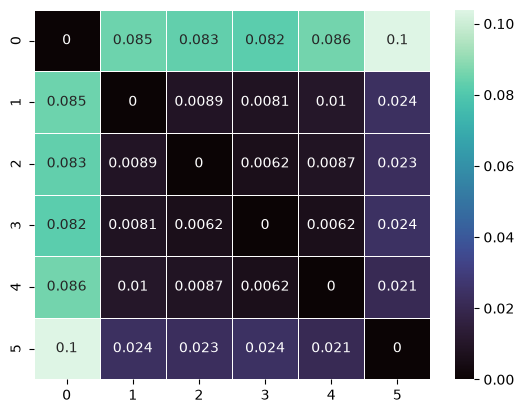

In [14]:
optimizer_result = ARX_optimizer(data, na_init=5, nb_init=10, na_bounds=(1, 50), nb_bounds=(0, 50))

results = []
history = 180
heart_rate_history = optimizer_result['na']
feature_history = optimizer_result['nb']
coefficients = {}
intercept = {}

for i in range(1, 7):
    training = data[f"fold{i}_training"]
    testing = data[f"fold{i}_testing"]

    arx = MISO_ARX(na=heart_rate_history, nb=feature_history, hist = history)
    arx.fit(training)

    coefficients[i-1] = arx.model.coef_
    intercept[i-1] = arx.model.intercept_

    actual_all = []
    predicted_all = []

    for segment in testing:
        predictions = arx.predict(segment)
        actual = segment[["heart_rate"]].to_numpy()[history:300]
        actual_all.append(actual)
        predicted_all.append(predictions)

    actual_all = np.vstack(actual_all)
    predicted_all = np.vstack(predicted_all)
    metrics = validation_metrics(actual_all, predicted_all, ["heart_rate"])
    results.append([i, metrics['heart_rate'][1]])

    print(f"Fold {i}: Heart Rate RMSE = {metrics['heart_rate'][1]:.2f} BPM")

mse_df, rmse_df = coefficient_deviation(coefficients, intercept)
sns.heatmap(rmse_df, annot=True, linewidth=.5, cmap="mako")



### Visualizing 9 random segments to compare results

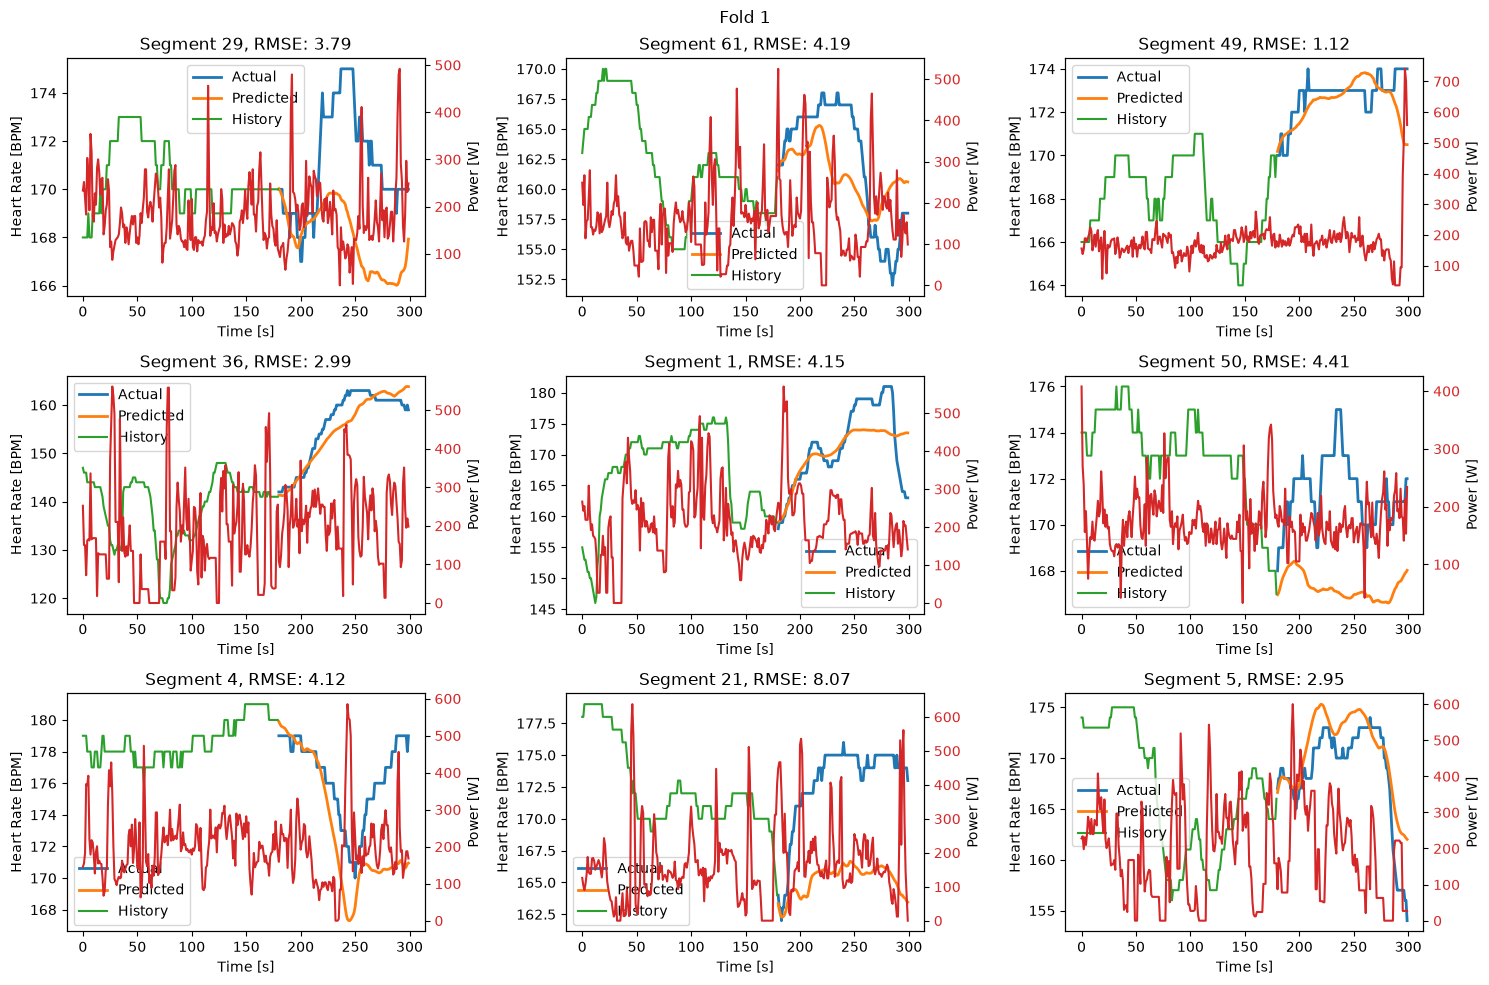

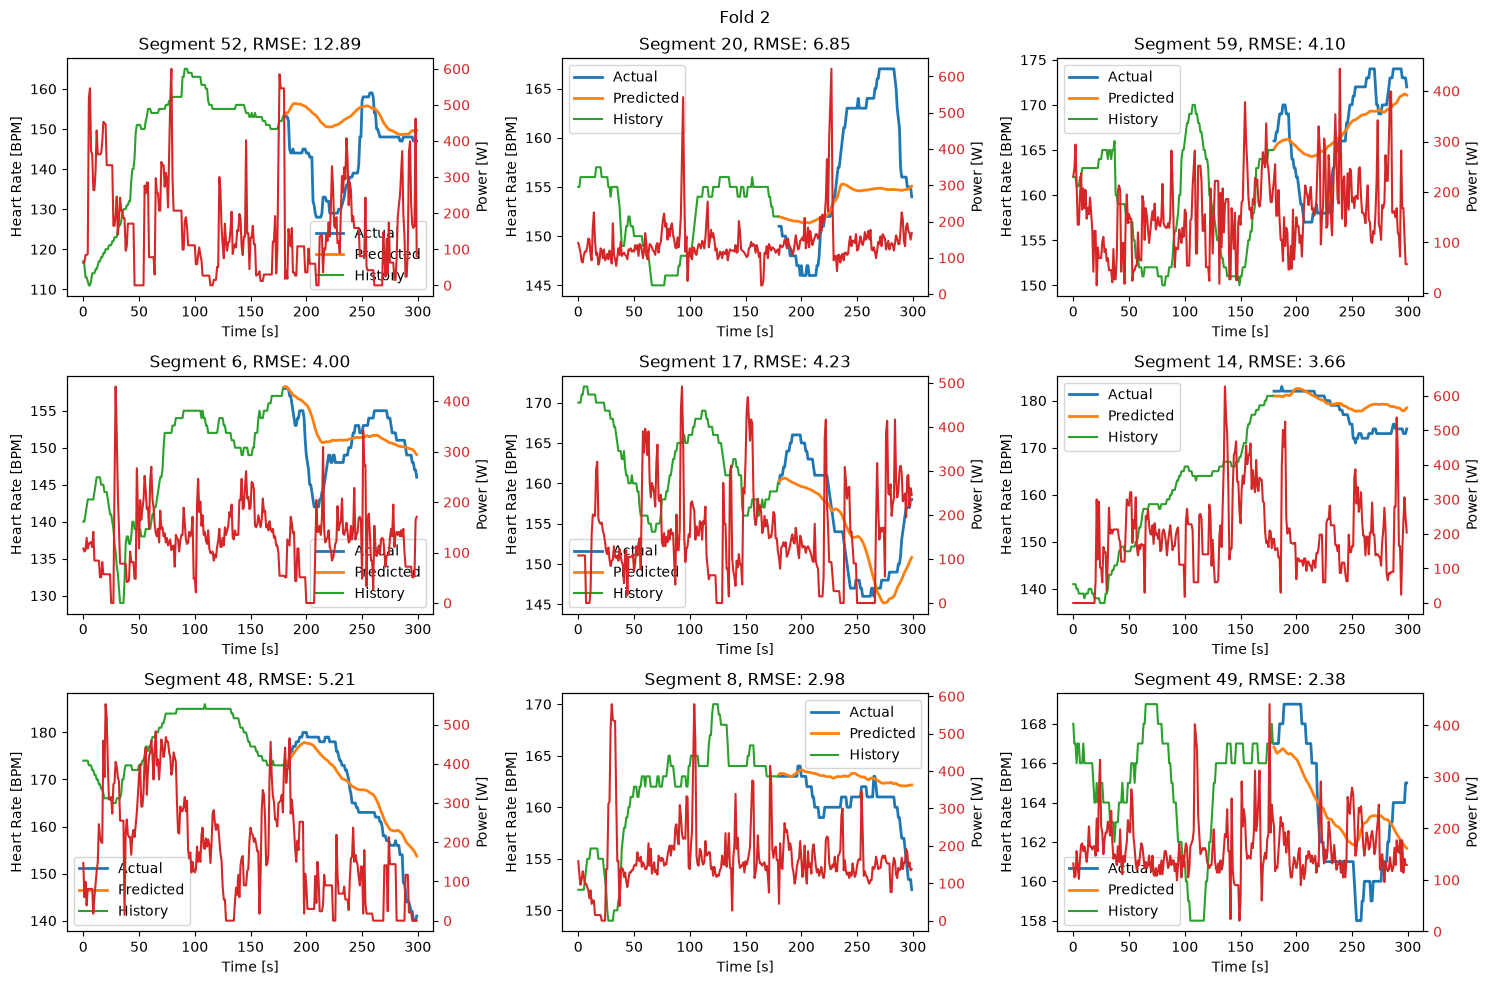

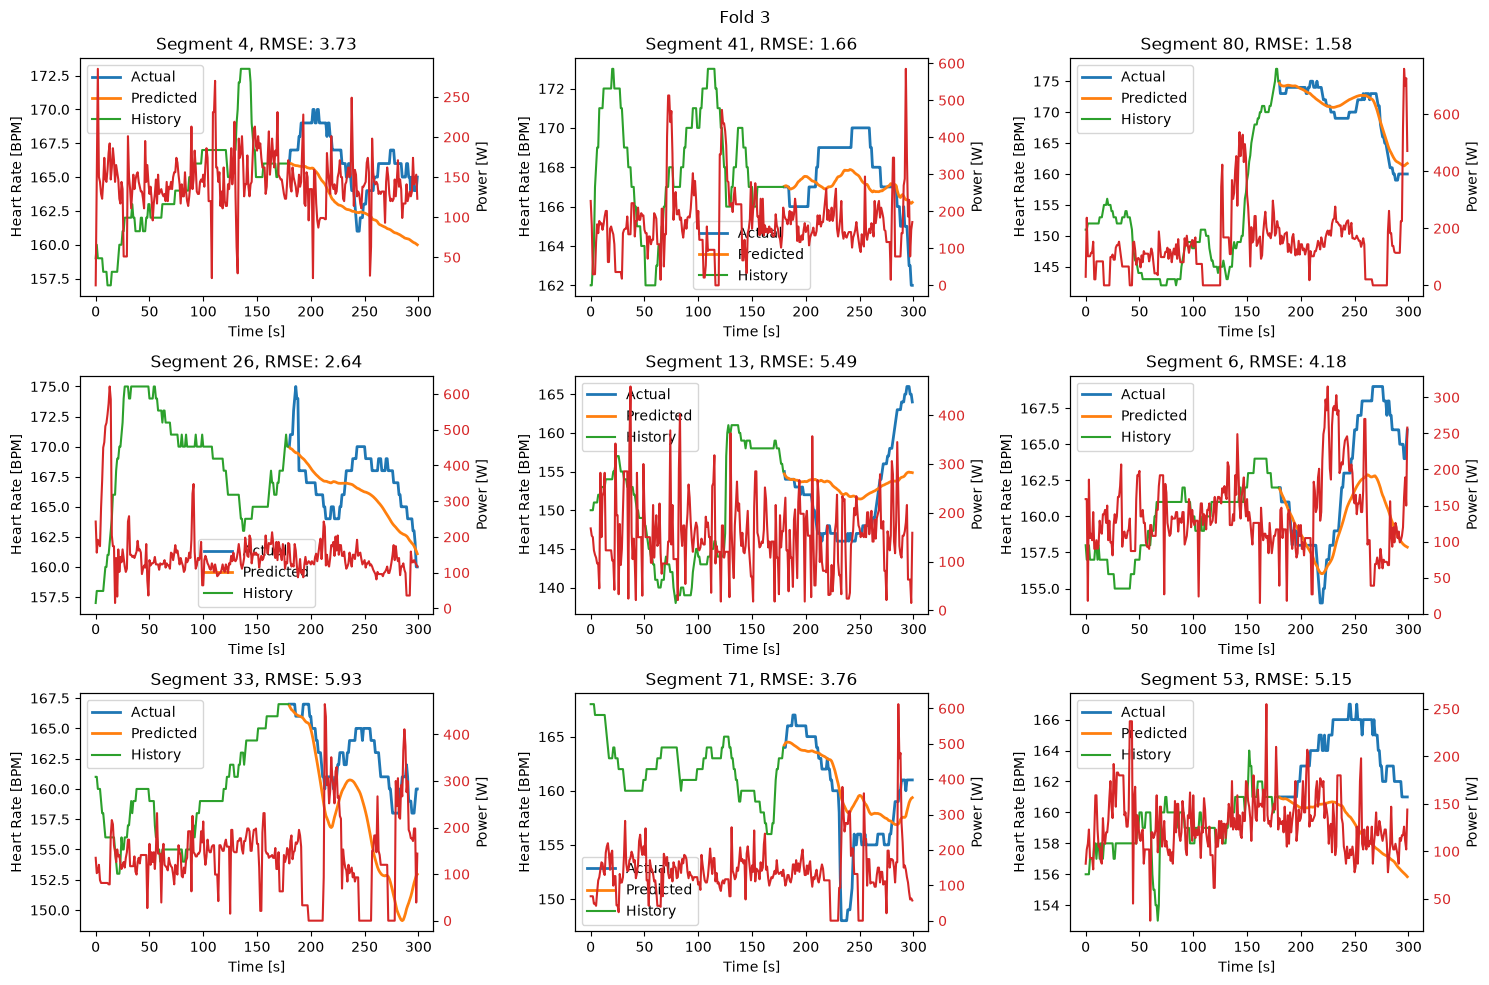

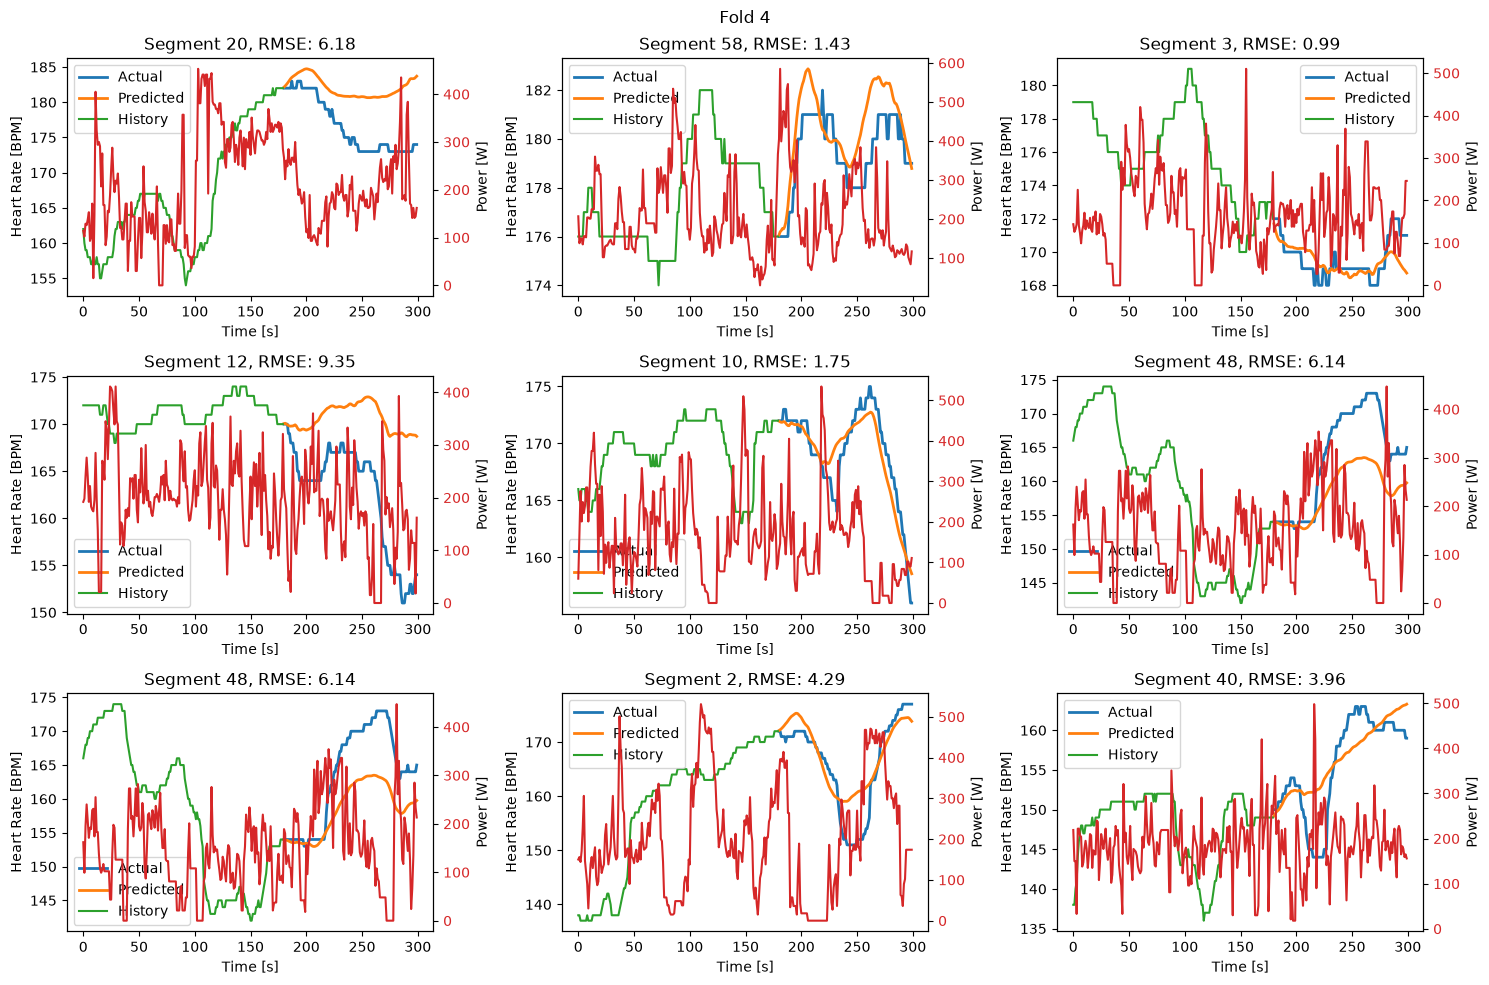

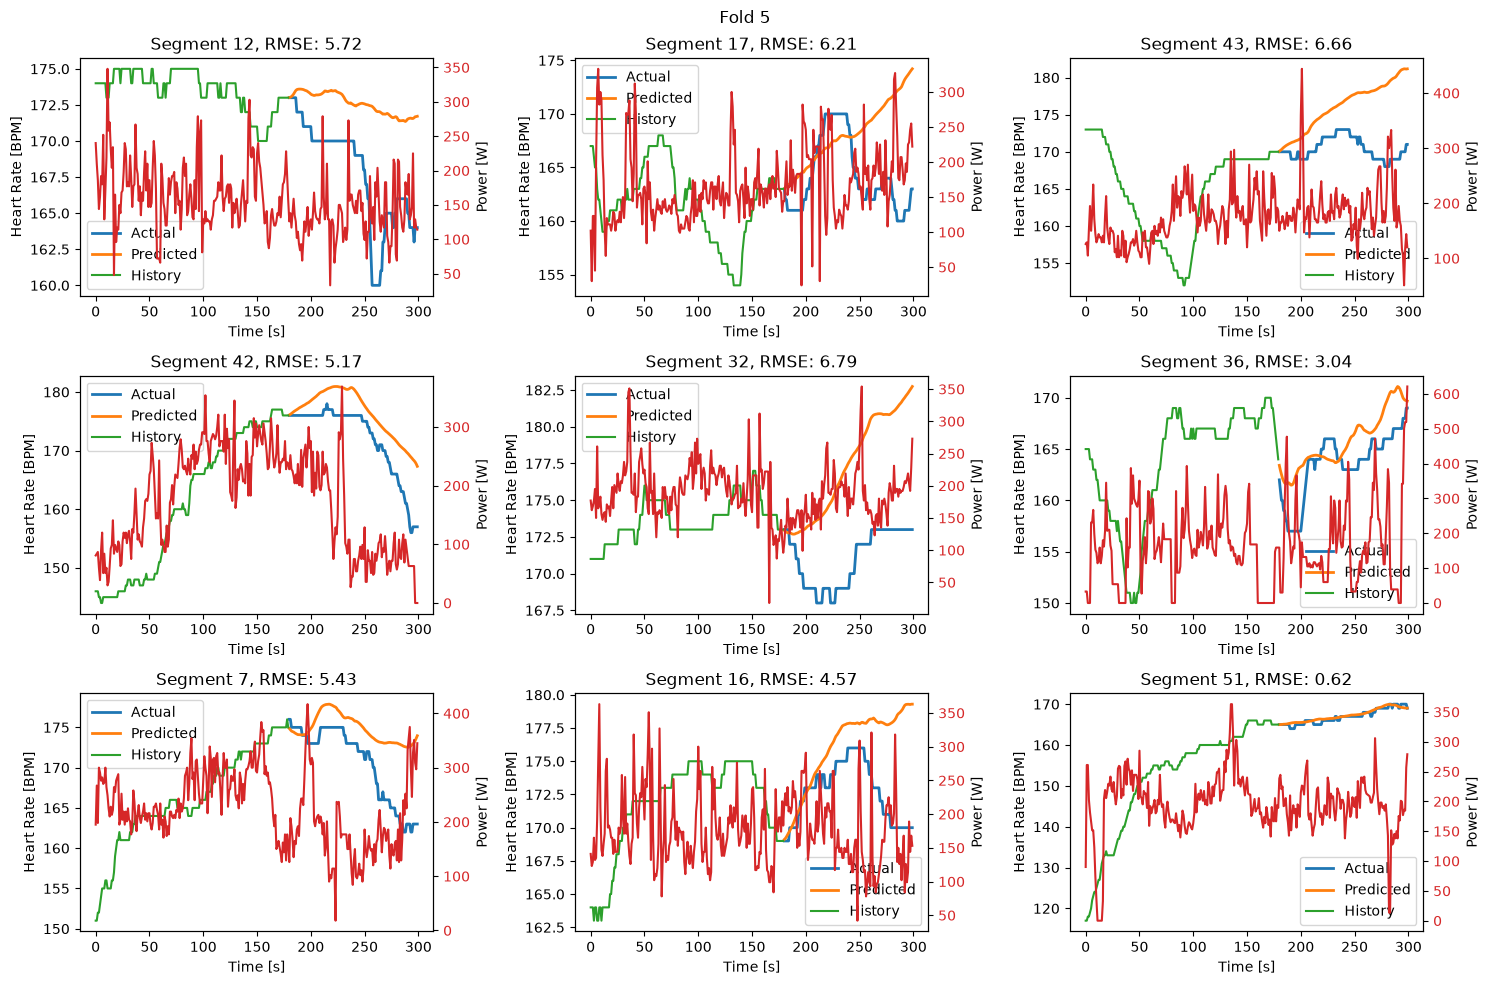

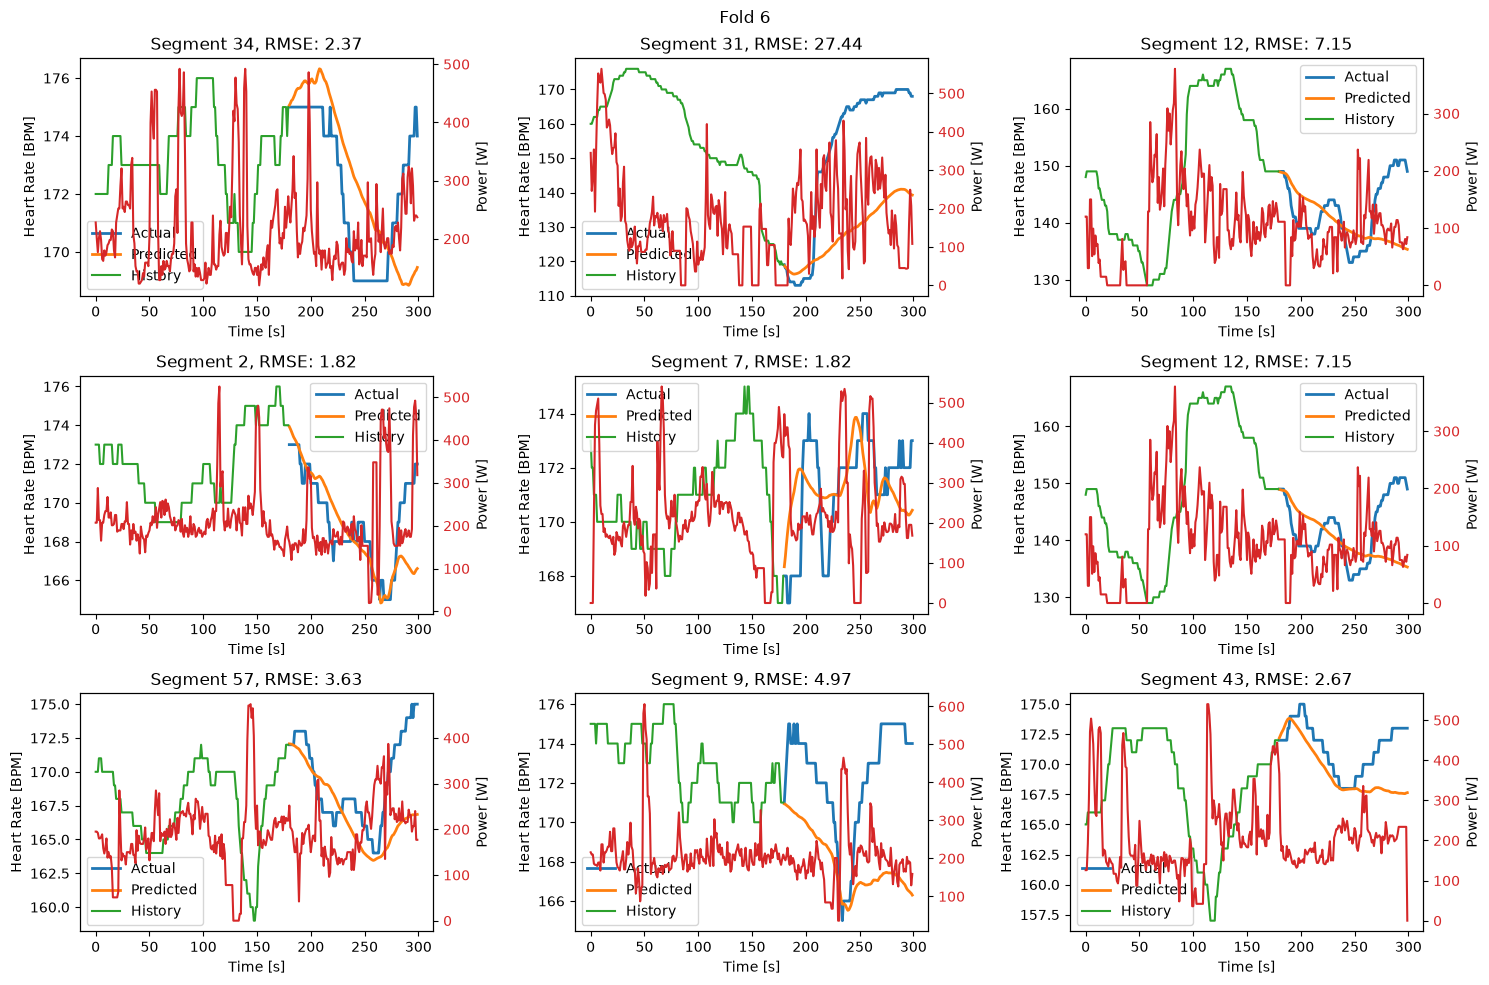

In [15]:
def random_visualizer_ARX(fold_idx, history):
    training = data[f"fold{fold_idx}_training"]
    testing = data[f"fold{fold_idx}_testing"]
    arx = MISO_ARX(na=heart_rate_history, nb=feature_history, hist=history)
    arx.fit(training)

    fold_len = len(testing)
    random_seed = np.random.randint(0, fold_len-1, size=9)
    t = np.arange(history, 300)
    t_tot = np.arange(300)
    t_hist = np.arange(history)
    fig, ax = plt.subplots(3, 3, figsize=(15, 10))

    for i in range(9):
    
        segment = testing[random_seed[i]]
        predictions = arx.predict(segment)
        heart_rate_pred = predictions[:, 0]
        heart_rate_actual = segment["heart_rate"].to_numpy()[history:300]
        metrics = validation_metrics(heart_rate_actual.reshape(-1, 1), heart_rate_pred.reshape(-1, 1), colnames=["heart_rate"])

        row = i // 3
        col = i % 3

        ax[row, col].plot(t, heart_rate_actual, linewidth=2, label='Actual')
        ax[row, col].plot(t, heart_rate_pred, linewidth=2, label='Predicted')
        ax[row, col].plot(t_hist, segment["heart_rate"].to_numpy()[0:history], label='History')
        ax[row, col].set_title(f'Segment {random_seed[i]}, RMSE: {metrics['heart_rate'][1]:.2f}')
        ax[row, col].set_xlabel('Time [s]')
        ax[row, col].set_ylabel("Heart Rate [BPM]")
        ax[row, col].legend()
        twin_ax = ax[row, col].twinx()
        twin_ax.plot(t_tot, segment["power"].to_numpy(), color='tab:red')
        twin_ax.tick_params(axis='y', labelcolor='tab:red')
        twin_ax.set_ylabel("Power [W]")

    fig.suptitle(f'Fold {fold_idx}')
    plt.tight_layout()
    plt.savefig(f"/home/xal-laptop/ECSE-4840_project/visualization/regressors/MISO_ARX/fold{fold_idx}_rand_vis.png", dpi=300, bbox_inches='tight')
    plt.show()

    return None

for i in range(1, 7):
    random_visualizer_ARX(i, history)
    
    

## L2 Regularized ARX - Sklearn Ridge implementation
### Evaluating across all 6 folds

In [ ]:


results = []
history = 180
heart_rate_history = 10
feature_history = 20
alpha = 1

for i in range(1, 7):
    training = data[f"fold{i}_training"]
    testing = data[f"fold{i}_testing"]

    arx = MISO_L2_ARX(na=heart_rate_history, nb=feature_history, alpha=alpha, hist = history)
    arx.fit(training)

    actual_all = []
    predicted_all = []

    for segment in testing:
        predictions = arx.predict(segment)
        actual = segment[["heart_rate"]].to_numpy()[history:300]
        actual_all.append(actual)
        predicted_all.append(predictions.reshape(-1, 1))

    actual_all = np.vstack(actual_all)
    predicted_all = np.vstack(predicted_all)
    metrics = validation_metrics(actual_all, predicted_all, ["heart_rate"])
    results.append([i, metrics['heart_rate'][1]])

    print(f"Fold {i}: Heart Rate RMSE = {metrics['heart_rate'][1]:.2f} BPM")


Fold 1: Heart Rate RMSE = 18.43 BPM
Fold 2: Heart Rate RMSE = 5.25 BPM
Fold 3: Heart Rate RMSE = 6.45 BPM
Fold 4: Heart Rate RMSE = 6.10 BPM
Fold 5: Heart Rate RMSE = 6.65 BPM
Fold 6: Heart Rate RMSE = 9.00 BPM


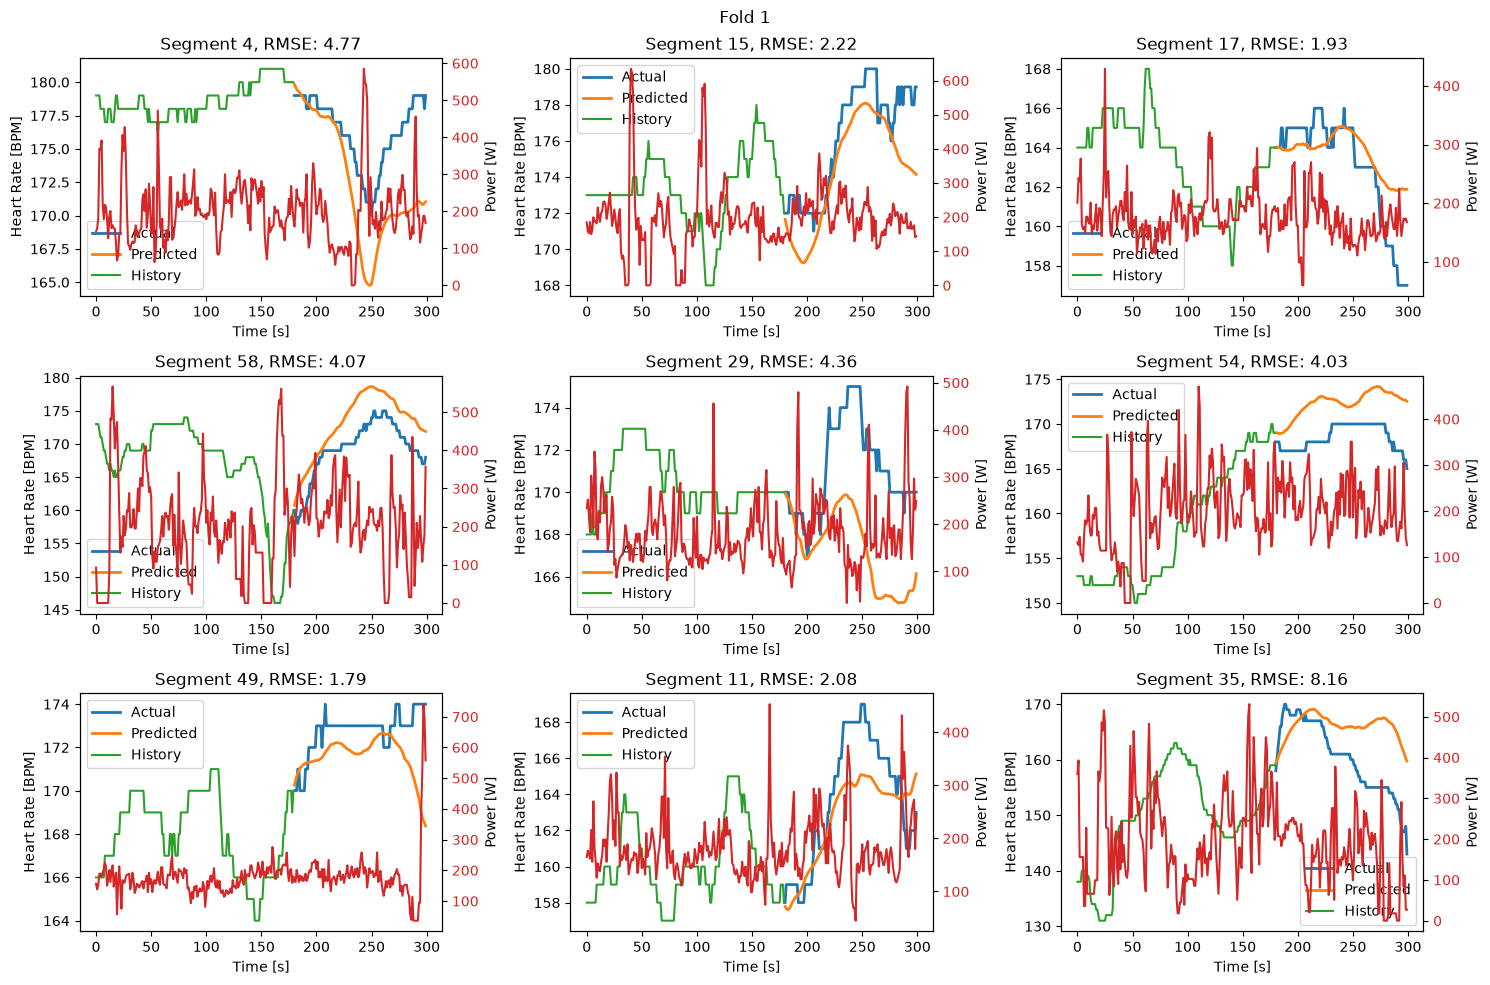

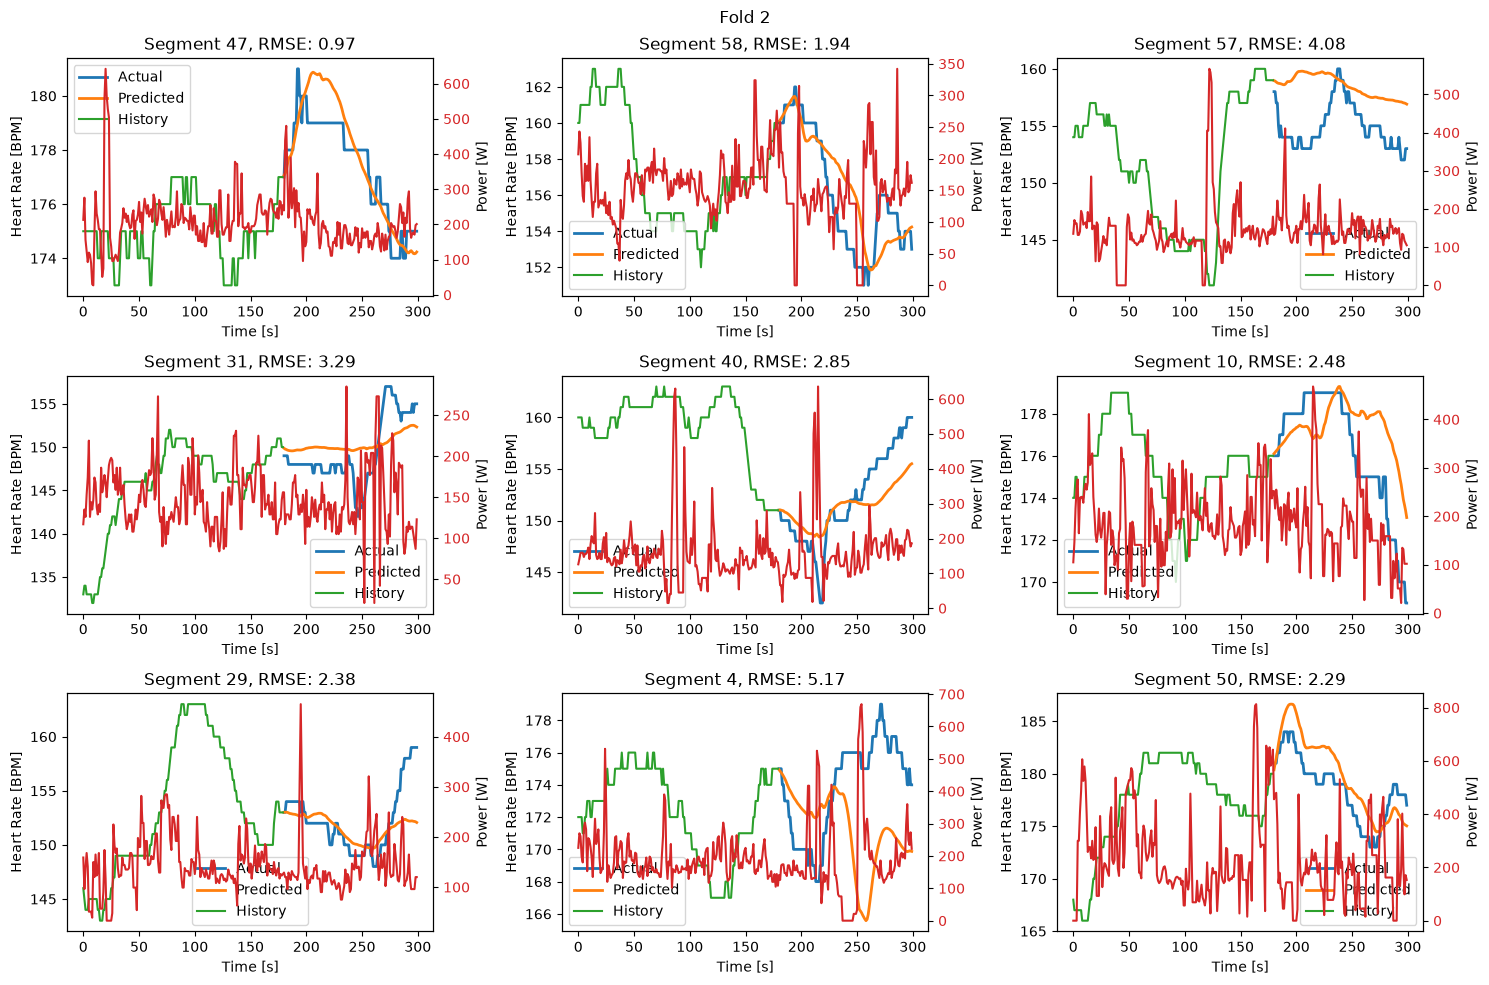

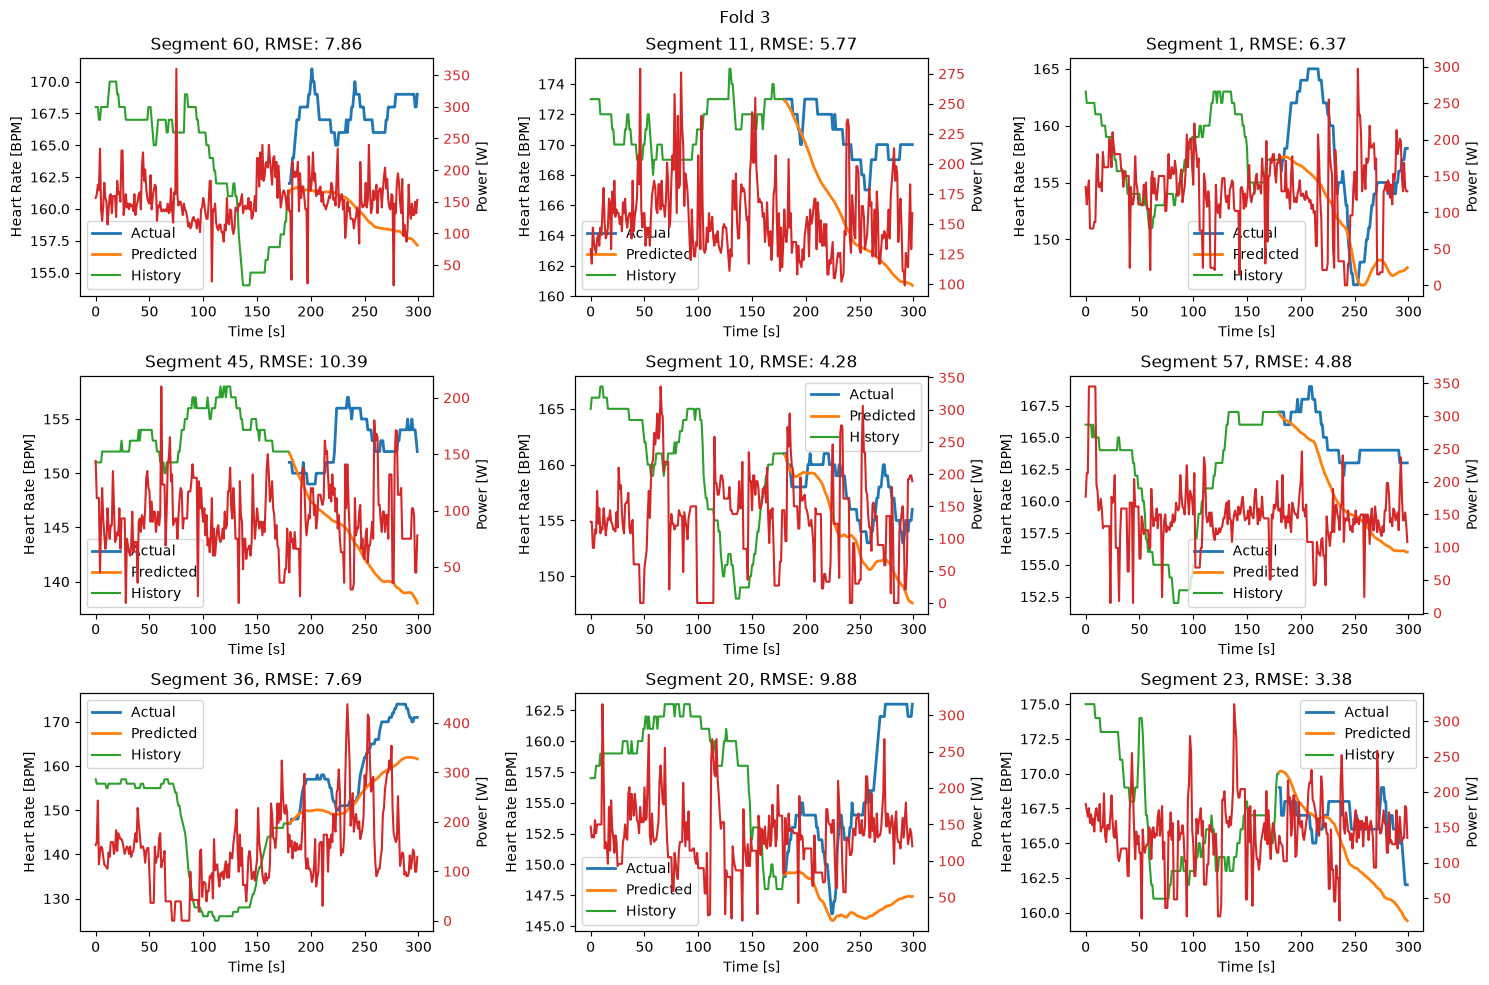

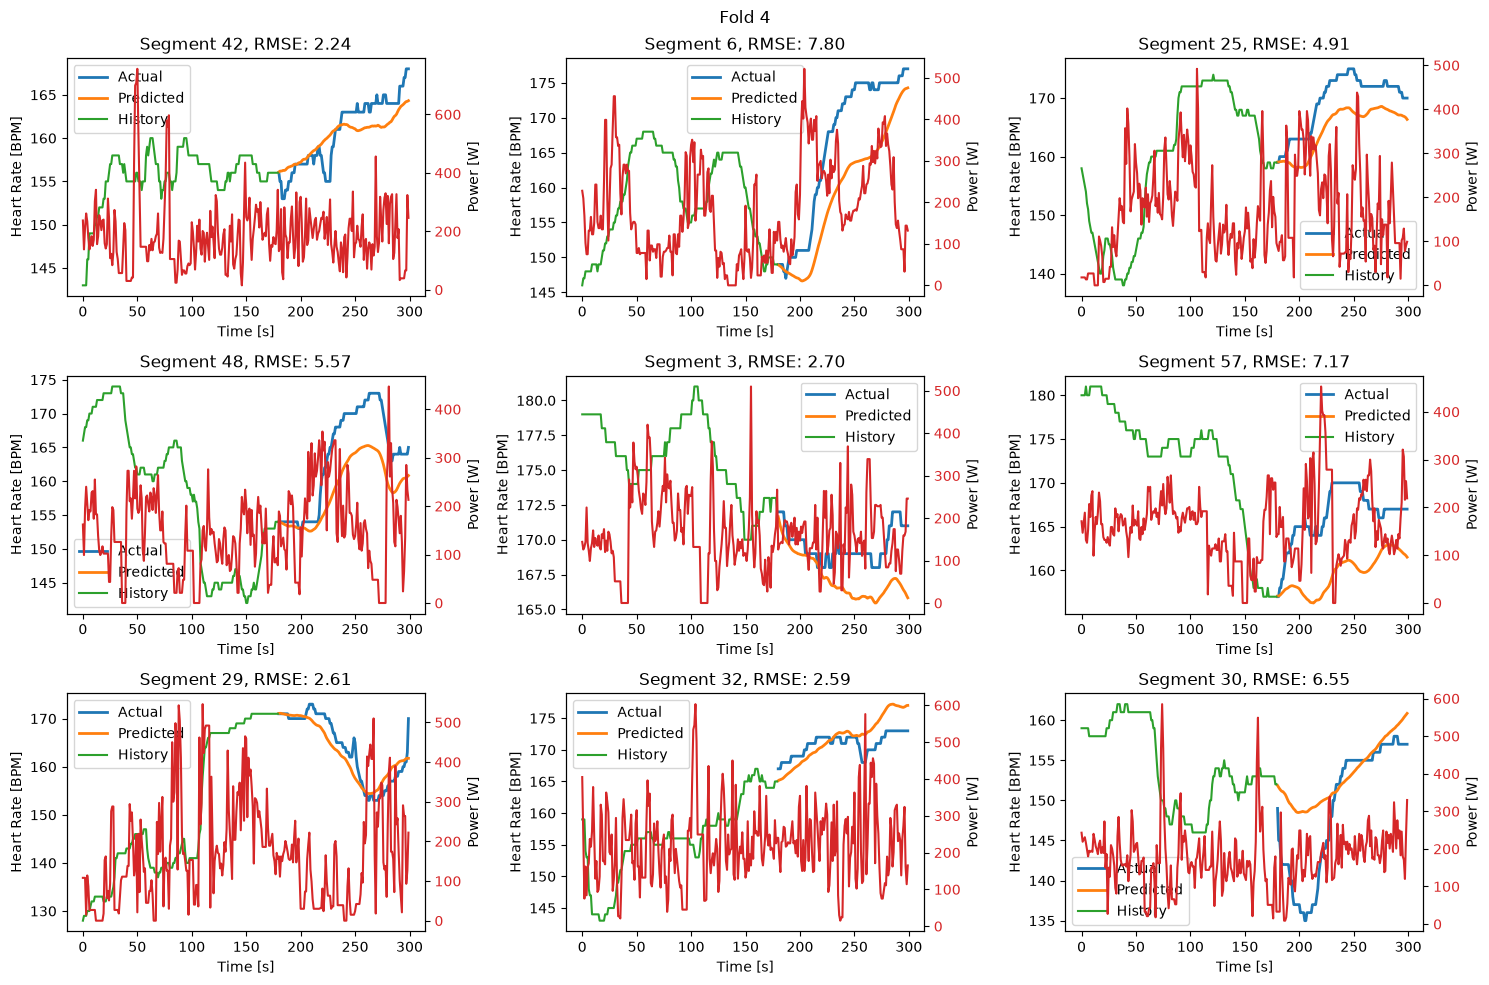

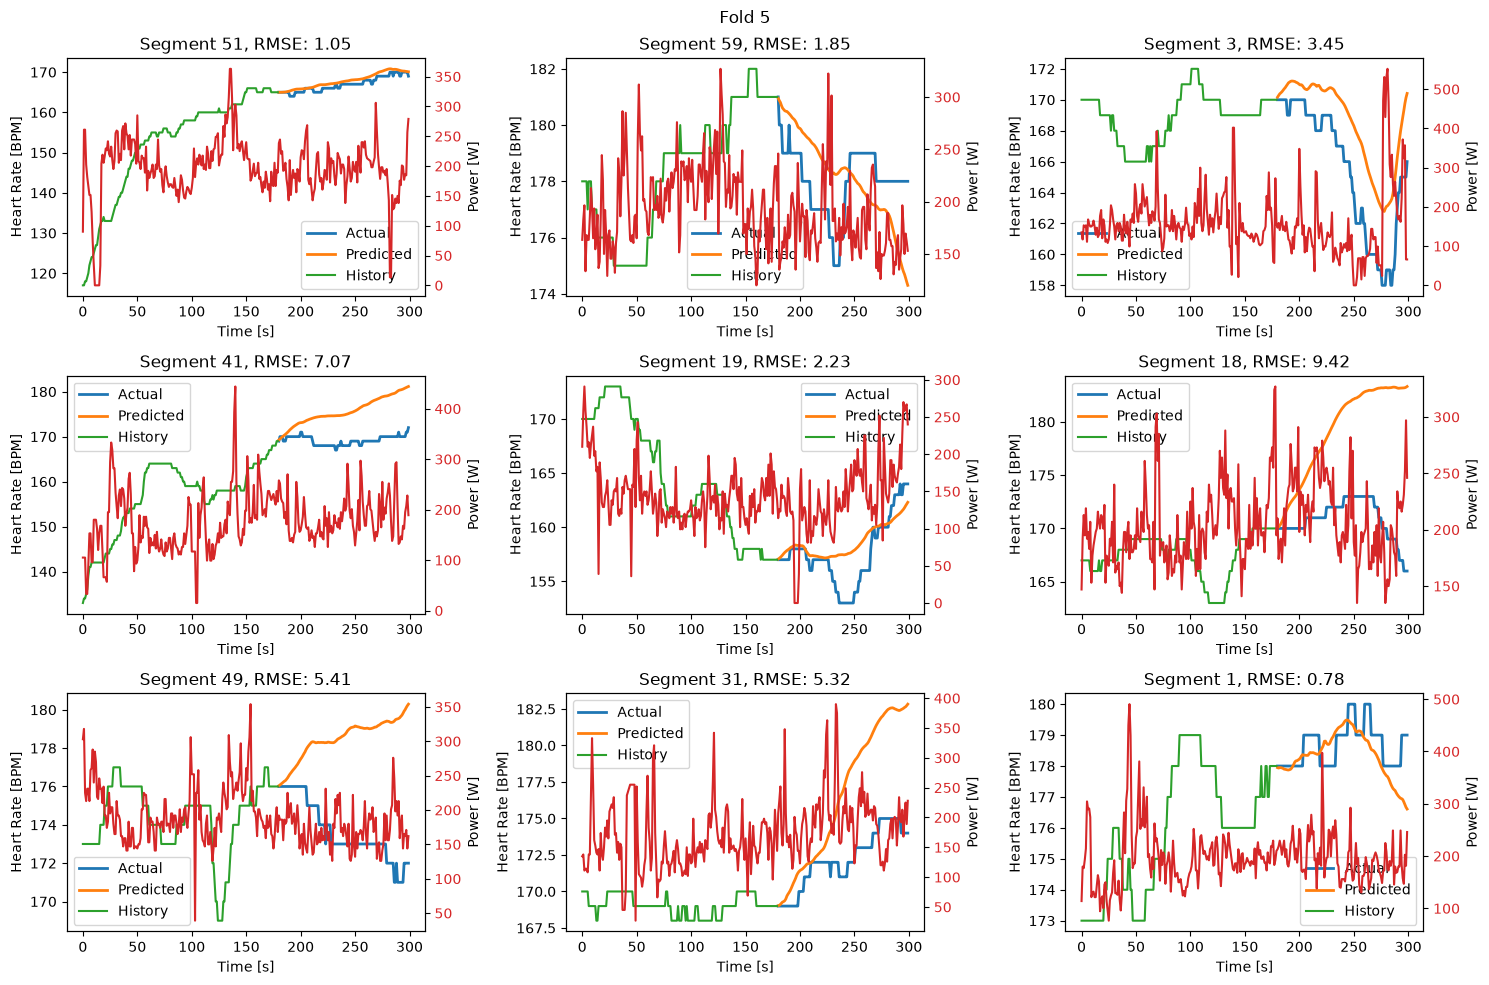

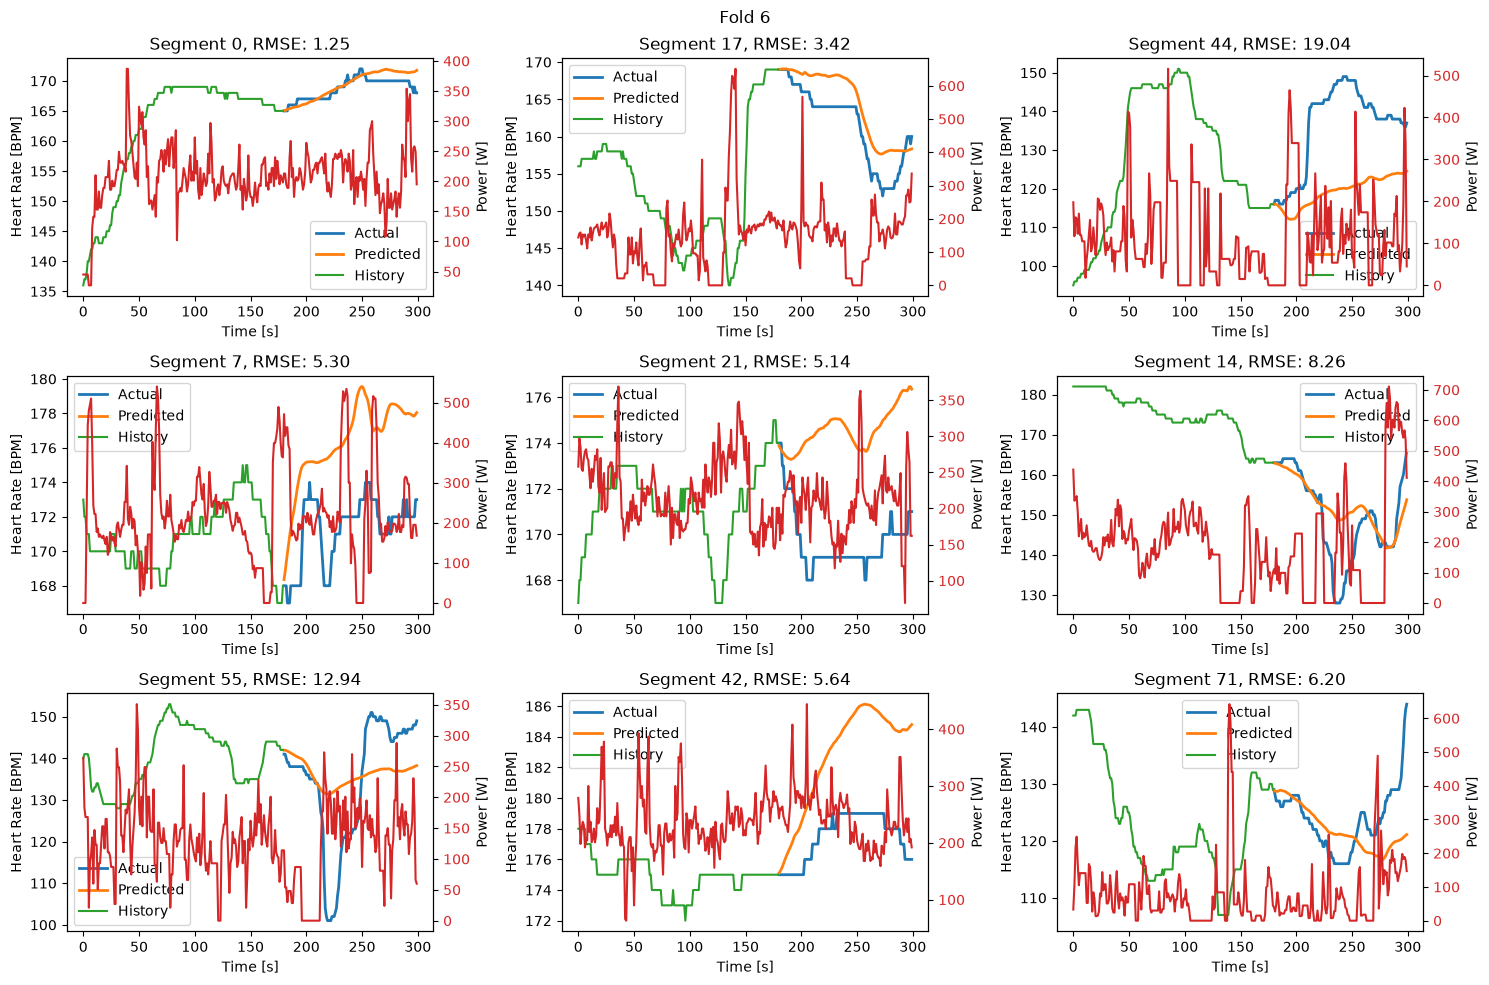

In [46]:
def random_visualizer_L2_ARX(fold_idx, history):
    training = data[f"fold{fold_idx}_training"]
    testing = data[f"fold{fold_idx}_testing"]
    arx = MISO_L2_ARX(na=heart_rate_history, nb=feature_history, hist=history)
    arx.fit(training)

    fold_len = len(testing)
    random_seed = np.random.randint(0, fold_len-1, size=9)
    t = np.arange(history, 300)
    t_tot = np.arange(300)
    t_hist = np.arange(history)
    fig, ax = plt.subplots(3, 3, figsize=(15, 10))

    for i in range(9):
    
        segment = testing[random_seed[i]]
        predictions = arx.predict(segment)
        heart_rate_pred = predictions
        heart_rate_actual = segment["heart_rate"].to_numpy()[history:300]
        metrics = validation_metrics(heart_rate_actual.reshape(-1, 1), heart_rate_pred.reshape(-1, 1), colnames=["heart_rate"])

        row = i // 3
        col = i % 3

        ax[row, col].plot(t, heart_rate_actual, linewidth=2, label='Actual')
        ax[row, col].plot(t, heart_rate_pred, linewidth=2, label='Predicted')
        ax[row, col].plot(t_hist, segment["heart_rate"].to_numpy()[0:history], label='History')
        ax[row, col].set_title(f'Segment {random_seed[i]}, RMSE: {metrics['heart_rate'][1]:.2f}')
        ax[row, col].set_xlabel('Time [s]')
        ax[row, col].set_ylabel("Heart Rate [BPM]")
        ax[row, col].legend()
        twin_ax = ax[row, col].twinx()
        twin_ax.plot(t_tot, segment["power"].to_numpy(), color='tab:red')
        twin_ax.tick_params(axis='y', labelcolor='tab:red')
        twin_ax.set_ylabel("Power [W]")

    fig.suptitle(f'Fold {fold_idx}')
    plt.tight_layout()
    plt.savefig(f"/home/xal-laptop/ECSE-4840_project/visualization/regressors/MISO_L2_ARX/fold{fold_idx}_rand_vis.png", dpi=300, bbox_inches='tight')
    plt.show()

    return None

for i in range(1, 7):
    random_visualizer_L2_ARX(i, history)
    
    

In [48]:
predictions

array([165.32199704, 165.61068399, 165.85633203, 166.02457929,
       166.19966098, 166.36704438, 166.48368723, 166.62130667,
       166.72213022, 166.86284147, 167.00253578, 167.10967054,
       167.20457955, 167.30991164, 167.42280376, 167.53750887,
       167.57502335, 167.65759795, 167.77214685, 167.86215531,
       167.99793583, 168.11680261, 168.21253023, 168.33400273,
       168.43024818, 168.55584403, 168.71455253, 168.86744429,
       169.08276571, 169.2635741 , 169.443062  , 169.58920847,
       169.68485574, 169.82025671, 169.93747705, 170.11115604,
       170.34079066, 170.60561301, 170.88483078, 171.12124478,
       171.306417  , 171.4324125 , 171.57803126, 171.74449792,
       171.88607187, 172.07273174, 172.23812452, 172.41646282,
       172.59082671, 172.68971638, 172.80238943, 172.89332808,
       172.99526335, 173.13412938, 173.22798842, 173.36501387,
       173.45186722, 173.50285335, 173.56136794, 173.56001909,
       173.5704996 , 173.59223069, 173.60771838, 173.62